# Lab 6 — Feature Scaling and k-Nearest Neighbors

**Course:** Machine Learning · BSc in Artificial Intelligence

| | |
|---|---|
| **Student name** | Omarkhaliyeva N |
| **Group** | Is |
| **Date** | 21.11.2026 |

**Completed lab: Parts A–E, checks and short answers.**


## How to use this notebook — read this first

**Cells.** **Text (Markdown) cells** explain what to do; **code cells** contain Python. Run a cell with **Shift + Enter**, **in order, from top to bottom** — later cells use variables created by earlier ones.

**Every code cell has a text cell above it with the same structure:**

| Label | Meaning |
|---|---|
| **What this cell does** | Explains the code in the next cell. |
| **Your task** | What *you* must do. "Just run it" means there is nothing to write. |
| `# TODO` | A line you must complete. Replace `None` (or the placeholder). |
| **Hint** | A tip if you are stuck. Try without it first. |
| **Expected result** | What you should see, so you can check yourself. |
| `# CHECK` cell | Tests your work. Prints **✓** when correct; otherwise stops with a message explaining the problem. **Do not edit CHECK cells.** |
| **Your answer** | A text cell for 2–5 sentences in your own words. |

**The three formulas of today**

| Idea | Formula | In words |
|---|---|---|
| Euclidean distance | $d(\mathbf a,\mathbf b)=\sqrt{\sum_j (a_j-b_j)^2}$ | straight-line distance, Pythagoras in many dimensions |
| Standardisation (z-score) | $x' = \dfrac{x-\text{mean}}{\text{std}}$ | every feature gets mean 0 and standard deviation 1 |
| Min–max scaling | $x' = \dfrac{x-\min}{\max-\min}$ | every feature is squeezed into the range 0 … 1 |

**The k-NN rule:** find the $k$ training points closest to the new point; **classification** → majority vote, **regression** → average.

**Before you submit:** *Runtime → Restart and run all*. Everything must run without errors and every CHECK must print ✓. Rename the file `Lab06_<Surname>_<Name>.ipynb`.

## Setup

**What this cell does:** imports pandas, NumPy, matplotlib and the scikit-learn tools for today: splitting, scalers, pipelines, the k-NN classifier, cross-validation and grid search, plus the built-in wine data.

**Your task:** just run it.

**Expected result:** `ready`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.datasets import load_wine
np.set_printoptions(precision=3, suppress=True)
print("ready")

ready


---
# Part A — k-NN by hand (≈ 20 min)

The example from the lecture. A new penguin arrives: **bill length 45.0 mm, body mass 4100 g**. Six known penguins:

| Penguin | Species | Bill (mm) | Mass (g) |
|---|---|---|---|
| A | Adelie | 38.9 | 3625 |
| B | Chinstrap | 51.3 | 3700 |
| C | Chinstrap | 52.8 | 4550 |
| D | Gentoo | 45.1 | 5000 |
| E | Gentoo | 52.5 | 5450 |
| F | Adelie | 37.7 | 3600 |

### A1. One distance on paper

**What this cell does:** stores the distance you computed by hand.

**Your task:** compute **on paper** the Euclidean distance between the new penguin (45.0, 4100) and penguin **B** (51.3, 3700). Type it with one decimal.

**Hint:** differences 6.3 and 400 → square → add → square root.

**Expected result:** ✓ — and notice how close your answer is to 400.

In [2]:
dist_B_hand = round(np.sqrt((45.0 - 51.3)**2 + (4100 - 3700)**2), 1)


In [3]:
# CHECK A1 — do not edit
assert dist_B_hand is not None, "Type your distance."
assert abs(dist_B_hand - 400.05) < 0.2, "Recompute: sqrt(6.3**2 + 400**2)."
print("✓ A1 — the 6.3 mm of bill difference adds only 0.05 to the distance!")

✓ A1 — the 6.3 mm of bill difference adds only 0.05 to the distance!


### A2. All six distances with NumPy and a k = 3 vote

**What this cell does:** builds the six penguins as a table, then computes the distance from the new penguin to **every** row in one line, sorts, and takes the 3 nearest.

**Your task:** complete the two `# TODO` lines.
1. `dist_raw`: the Euclidean distance from `new` to each row of `X6` (an array of 6 numbers).
2. `nearest3`: the **positions** of the 3 smallest distances.

**Hint:** `X6 - new` subtracts `new` from every row (broadcasting). Then square, `.sum(axis=1)`, `np.sqrt`. For the positions use `np.argsort(dist_raw)[:3]`.

**Expected result:** distances `[475.0, 400.0, 450.1, 900.0, 1350.0, 500.1]`; nearest three are B, C, A → vote **Chinstrap**.

In [4]:
six = pd.DataFrame({"species": ["Adelie", "Chinstrap", "Chinstrap", "Gentoo", "Gentoo", "Adelie"],
                    "bill": [38.9, 51.3, 52.8, 45.1, 52.5, 37.7],
                    "mass": [3625, 3700, 4550, 5000, 5450, 3600]}, index=list("ABCDEF"))
X6 = six[["bill", "mass"]].to_numpy(dtype=float)
new = np.array([45.0, 4100.0])

dist_raw = np.sqrt(((X6 - new)**2).sum(axis=1))
nearest3 = np.argsort(dist_raw)[:3]

six["dist_raw"] = dist_raw.round(1)
print(six)
print("3 nearest:", list(six.index[nearest3]), "→ vote:", Counter(six.species.iloc[nearest3]).most_common())


     species  bill  mass  dist_raw
A     Adelie  38.9  3625     475.0
B  Chinstrap  51.3  3700     400.0
C  Chinstrap  52.8  4550     450.1
D     Gentoo  45.1  5000     900.0
E     Gentoo  52.5  5450    1350.0
F     Adelie  37.7  3600     500.1
3 nearest: ['B', 'C', 'A'] → vote: [('Chinstrap', 2), ('Adelie', 1)]


In [5]:
# CHECK A2 — do not edit
assert dist_raw is not None and nearest3 is not None, "Complete both TODO lines."
assert np.allclose(dist_raw, np.sqrt(((X6 - new) ** 2).sum(axis=1))), "dist_raw is wrong — subtract, square, sum over axis=1, square root."
assert list(six.index[nearest3]) == ["B", "C", "A"], "nearest3 should hold the positions of the 3 smallest distances, in order (np.argsort)."
print("✓ A2 — k = 3 predicts Chinstrap")

✓ A2 — k = 3 predicts Chinstrap


### A3. The same vote after standardising

**What this cell does:** standardises both features with the mean and standard deviation of the **whole penguin data set** (given below), then repeats the distance calculation.

| | mean | standard deviation |
|---|---|---|
| bill length | 43.9 mm | 5.5 mm |
| body mass | 4201.8 g | 800.8 g |

**Your task:** complete `X6_s` and `new_s` (the standardised penguins and new point), then `dist_std` exactly as in A2.

**Hint:** `(X6 - mean) / std` works on the whole array at once when `mean` and `std` are arrays of length 2.

**Expected result:** now **D (Gentoo)** — the one with the same bill — is the nearest penguin. The ranking changed completely, although no penguin changed.

In [6]:
mean = np.array([43.9, 4201.8])
std = np.array([5.5, 800.8])

X6_s = (X6 - mean) / std
new_s = (new - mean) / std
dist_std = np.sqrt(((X6_s - new_s)**2).sum(axis=1))

six["dist_std"] = dist_std.round(2)
print(six.sort_values("dist_std"))


     species  bill  mass  dist_raw  dist_std
D     Gentoo  45.1  5000     900.0      1.12
B  Chinstrap  51.3  3700     400.0      1.25
A     Adelie  38.9  3625     475.0      1.26
F     Adelie  37.7  3600     500.1      1.47
C  Chinstrap  52.8  4550     450.1      1.53
E     Gentoo  52.5  5450    1350.0      2.17


In [7]:
# CHECK A3 — do not edit
assert dist_std is not None, "Complete the TODO lines."
assert np.allclose(X6_s, (X6 - mean) / std), "X6_s: subtract the mean, divide by the standard deviation."
assert six.index[np.argmin(dist_std)] == "D", "After scaling the nearest penguin should be D — check new_s (scale the new point too!)."
print("✓ A3 — nearest after scaling:", six.index[np.argmin(dist_std)], "(Gentoo)")

✓ A3 — nearest after scaling: D (Gentoo)


**Question A:** before scaling, which feature decided the distances? Why is that a problem, and what would happen if mass were measured in **kilograms** instead of grams?

**Your answer (A):**

Body mass decided the distance because grams are much bigger numbers than millimetres. This is unfair to bill length. If we use kilograms, the result can change. Scaling makes both features important.


---
# Part B — k-NN from scratch (≈ 25 min)

k-NN is short enough to write yourself. Then we check it against scikit-learn on real data.

### B1. Load the penguins and split

I used the penguin data included in this notebook, so it also runs without internet. The split is 75% training and 25% testing.


In [8]:
# Offline copy of Palmer Penguins (same data used in the lab)
import base64, zlib
from io import StringIO
_penguins_data = "eNqVW8uOZLcN3edbCg29qMcycYD8QPaDiac8bqDnge5ZxH+fK1KUbpV4RcWLsY25oig+Do8o1sfP+++v94/b68fb5+9fbv95fXv79Hb//vXXn5++faP//XL/Sf/3x9vrz5/39/Pf//jy16dvnz8+Pn29fdz/e/vr/vn9b3//cn97vd/+/eP96/394/795suLvdn8ko4/7Iu5+QTm+Ne3z2/3mzMmiSvgZtNLOFbEuiKbuuKP+2JNMC++7mJutkBd40Bdg/9cqBCrvqXKLL6KC7o4Xz935iUea+rHPqoHzS+lHjSzaaKDjV1c1Sy2g4aYQNklkANsPwuuuDKkO/7uOIVrpwhkyCvZqHzCDdBV3mx8XT2FFkqrr4OtYlM9aXboUj0MDovGm7OovR2hs7YOrqjWqeETgroiVpXIazBOoemF8dTDcyOeDk9A9URdmKpmsHGWmjP4R0Bv6PEUqtuO8x8ZVwL6W97lH68fv/+4Nxfm6sKEW4Srw48FidOfsmItH2pKYIznssx9XpDxW4xAtGyBpfxMIehYnaypg7By6JTTjjoB8z/jH5hssFTn+Byhrst3ujlLk58wKSyoCgGfwCzs88/3++dvDXoR/FJewmj7PnXr0/fFqNIpgvJAi0vph+6FdQ+69FgDP40cu4z+ro3jzK9JEOzSMjVwnEHpuh2P3EW7AFsdVDvGVm+oEiiWOXTP9XvbLBMirC0DrTjmddB0u+eGI2RJze6Gz4o1wCpexXpUENfiAnG7ZUyNyML5bVTLYAJmrl9xJZ1qTBmWCQ6WunAupbrGlbmSnm2CuUrREhSLu8odRt26ikVGgUIlKLHJ4ckoeUYBy5mEVc4/WCXPsLdWf5LvMDGwYKHVDSzlBzKkbbDniqa/pcoWua6ntf6F9O8hCaDap0eNn8vCJD8STMaWri4r8jm/bauyTyRYsH96CHoLqn08YxnMOSWrg5lF8qNuf4yfGp9uw78NihmeVPsc8iPTdzejq2AftL/rUA87+hNeYvxb2T4nLoVEJA42b662eGCsiMqhc0nQdvFIvEZVuXTEww0gMTqbGZ3lFbGRnrJOh9NZgGpAYfZpQbcYtKQrRuLFWeS4udUOilun7UKcIKKh7eYuxFLK4MW6xTC2YgeoLYu5HmN0FqPuErpfiOy6LYuVdiui6pk2zpIatskcVval5Uj2860gT3XRN15HPrlMx1518absGQ0BVtIjfjjiKpv110yQyaaXpbHzOv9w4ShLXaiEdnZxna/teyDb1yu1W8bRmY/UwugMLOp0kx6ozPW7T1C0adyIb+tX+NQt6fi2niROmmXWWI6/y7rupMbA16RK94wUqLtf6u6r9NjvJdcEo0n3na9TfbPb/Ajdmp6uGmWuP4ZuD85gPqUHnlnESzPxaqQjJq3l47X8dDt5wtFyfYvE9HZF0Z9rTr+JwVp+HgWnDLqzkF+pxcPtyijyLfMXBByr2If8S3UWq1lKoMpHkoeF3GfNv1C7SIRodr51yOZEJxPdfAb+MvNrxxiI+ru1/oXUSQzIRZefWluHssvI8p86bc0FYoYVsQ4j7kMPC3UXIEMZRmcP6i6Mob0CeKft0pDOMdJZ2DkLdvQyhwjIHn9gLq6dJUXpUiWfJRAutfqRNyx27ILkla4+ZmMXalpjdpSZucjez8xCMMDcVQI+nAU4xoTaVkTeyvWNdtk5S+t216am2T0LPFx2vdPP4okfuZaPV97vlbSzXC9xkiL3GThPQpC9fq6k1CdPo4dxKZ376qBgbWcwkb9eQ22v04jktnUCfFnq3ro7cMVgysRgEvvKL+rcSZcWP35DOuXBCQfWdke+j5ce6mZeRmeXzljWGI9bW8bzPcdJfa/ZMob77DC/PhWh93liX2s70ovH6V0hrGOAu1/56rVjPmt+eKFKijad9SaJOc7xDoyhVkKEf92///rxo5dCZI0ee8N2PLucW3ePC1BXWy8pztf/hPTUcXySjz6qKNUAam4NSvIBFcob8hEJaoPN2Wp8COvPMfk8fo7qgKLOQXVClR/ZPlmxT8D7J2CDqgYpuLVCvga+PzZxpoxW1lJ+rvIDH/i5d/r0OTYQ/KGTs6fW+UJ+If9Wh9XQA1jLBzLovvw8DFqjH7ImP/PnZlzNl/r7ap+qUNqQj63cU0BY3T6uxaerARG9FnCuxSf5V42fTPFz2N9V3cAv9QdD8v1mumCn45QuRg834AV+Mz7R/rnvoNkf49P+HwrZZp8W/+sDB9Lft3BuV90LKMHMMiw5goJs3fKnpxcd2Y4FePfTMiuRIT0HgtMMiYniONCSUZGNQ8Gk4aiF/oXvQIT8UfFsIfmZjzt39SVkiMM+z1396cCRkQcjs2jyA7XpBzLDUn4gZIi9waPrnxry4ALwoOifmv4mj1bcQj7aHwcYkEpBWtsHqLIkjs+5oSXJp/inXutSf8Cbbb16tfiE9XE9uas0XA5FU6dVlnKF/CuFYCN+AiGP50JkdYXcA7L5tfxIzMSx/lmPH2hUieLfa/7F/AqdWen2sc2/7gS1C/2B5e86zDRmQvobLSBy8++5gaoFBOlvNvT3o/JmiXkK9gkMuGEjoFt+ZZavxSdTgdKYg+7fxPEftvwbOvPxdq5f+YJZuQaHIen4kOmOJjL/q+OGR2Z4Ibk9cDqHyJw1z0LTHANB1RwMIXONHL/h2dQ/PwPh0rMYOZE9q0RmJiDpn9utRMzMaDcCLTzqb1Tk4cpCnlXsn7r9iWpEzf6WGsxc2aPRIt+1zMJT6PYHer8M7N+y9m8ZJBifP+LUQnrS3xHydIcFWN6p07jiuPH8sZDfmGFh5PFr+a1y5S5/ajhM8tskqnPITOK6J+BJ/9DuFJN/y+xfz1CSZ2QrF/FjWP+cVPvbM/MEAF0+xX+WmKEgv3XOmn3CWn8Yd6It+zO+WfZv1PyL8vudOm/5F5HfxbnnIKgTmMggPpSn1twEJ6WFs9tyF1/xAz//qfll+QGqMRO3tk8e/i1b9gGaIjCb8Z8In/mSHIp24DKYFcoHTT4zh4bPjgfritjtieO2q0i21G3rnD9pmetHKJQN+Z4S3TDnAT0U+LZuNuQzhXfcfDJGzazMyFlm5C8icyD5XupWCZEJD91O0LqpjrudyJm9hmxAkT8q7wYyjOZWS8ULy2fmVG6uuXLMn/p4RclZ/jmJHLHUFoFN8AoMXniPTKCAr2M25CQ2JIRI4RTyErj/9ufr949f759/cgc9jhcyJ71fpWkJFfDSxzWmEeJpge1zOPQG8NxrmpQCehpN/PwC07j3tIcbb7ZpfoER93D8kCF2JJJkK56UvJqgl4+ex2Ni0o7eJq4Lv6TazT3Q8XSSZNQ9+Fcu54lYZY/0MNaVkmJeegzH01/8kkZwoeEBKTsPooouLPwGSJP4CfTYBfqJ1eYeYGiugadLvNeCPfcHsmz3Dk5XmNO8VNBDsT3yOXkoWFjguB/Iv0fT1cpj6NOOJ9bFAk83k3g1+i2aN56HEaff7Ai26q/EIP+aQo6r04CQ1X0O9Cba3rnnZoTgjzbs25Y8Xypln6fVrKtwjsyDZjCe8xZ7mD7nLP8CSdiDLrq4kZUG/YS44l8VtUlCUPewlOeZGbPV9mgTavy7yKffmWUJfIAf2Is0IyUuiecJFp9hwx+GJrG456n7vM+d49oNn7ch8tJ9rtuKf61hjTTzKijl+PcUaRTnpVKGfshnH2fOF3u08XHTF5i9PSjPcUmcyKWwJD8MAzw3LoQF9vGnMBO7ujJv73Z4hV9Bm1Do+eEUpYjkI1BTNdcPHtpIY+Bwn6ecBLUC45Wdw6RILkyslpfqh2jeRD8Ga3lutD0chYm/wpIi5aDjoe00SufyHFyj2nQbbPjccw5unYOeqQng3FwMRKV6FQwS3xUdWPhXWXHLge1yDTw6GfWDjwnNAntLAOhnMrm9s04DOQJnACZ9bjsHI3MfL42aysBQxtygNXsOTJ1RTzn4P/ZCJbM="
pen = pd.read_csv(StringIO(zlib.decompress(base64.b64decode(_penguins_data)).decode("utf-8")))
pen = pen.dropna(subset=["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"])
X = pen[["bill_length_mm", "body_mass_g"]].to_numpy()
y = pen["species"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
print("train", X_train.shape, "| test", X_test.shape)
print(pd.Series(y_train).value_counts().to_dict())


train (256, 2) | test (86, 2)
{'Adelie': 113, 'Gentoo': 92, 'Chinstrap': 51}


### B2. Write `knn_predict_one`

**What this cell does:** defines a function that predicts the class of **one** new point.

**Your task:** complete the three `# TODO` lines:
1. `d` — distances from `x_new` to every row of `X_tr` (as in A2);
2. `idx` — the positions of the `k` smallest distances;
3. return the most common label among `y_tr[idx]`.

**Hint:** `Counter(labels).most_common(1)[0][0]` returns the most common element of a list.

**Expected result:** the test cell under the function prints `Chinstrap` for the toy example (k = 3).

In [9]:
def knn_predict_one(X_tr, y_tr, x_new, k):
    d = np.sqrt(((X_tr - x_new)**2).sum(axis=1))
    idx = np.argsort(d)[:k]
    return Counter(y_tr[idx]).most_common(1)[0][0]

print(knn_predict_one(X6, six.species.to_numpy(), new, k=3))


Chinstrap


In [10]:
# CHECK B2 — do not edit
assert knn_predict_one(X6, six.species.to_numpy(), new, k=3) == "Chinstrap", "With k = 3 the toy example should give Chinstrap."
assert knn_predict_one(X6, six.species.to_numpy(), new, k=1) == "Chinstrap", "With k = 1 the nearest is B (Chinstrap)."
print("✓ B2")

✓ B2


### B3. Your k-NN versus scikit-learn (scaled data)

**What this cell does:** standardises the data with a `StandardScaler` fitted on the **training** set only, predicts every test penguin with **your** function (k = 5), and compares with `KNeighborsClassifier(n_neighbors=5)`.

**Your task:** complete the two `# TODO` lines: `my_pred` (a list comprehension over the rows of `X_test_s`) and `my_acc` (the share of correct predictions).

**Hint:** `[knn_predict_one(X_train_s, y_train, x, 5) for x in X_test_s]`; accuracy = `np.mean(np.array(my_pred) == y_test)`.

**Expected result:** your accuracy ≈ **0.94**, the same as scikit-learn, and the two models agree on (almost) every test penguin. (They may differ on a rare 2–2–1 tie, where the tie-breaking rules differ.)

In [11]:
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)

my_pred = [knn_predict_one(X_train_s, y_train, x, 5) for x in X_test_s]
my_acc = np.mean(np.array(my_pred) == y_test)

sk = KNeighborsClassifier(n_neighbors=5).fit(X_train_s, y_train)
sk_pred = sk.predict(X_test_s)
print(f"my k-NN accuracy:      {my_acc:.3f}")
print(f"scikit-learn accuracy: {np.mean(sk_pred == y_test):.3f}")
print(f"agreement:             {np.mean(np.array(my_pred) == sk_pred):.3f}")


my k-NN accuracy:      0.942
scikit-learn accuracy: 0.942
agreement:             1.000


In [12]:
# CHECK B3 — do not edit
assert my_pred is not None and my_acc is not None, "Complete both TODO lines."
assert len(my_pred) == len(y_test), "Predict every test penguin."
assert np.mean(np.array(my_pred) == sk_pred) >= 0.97, "Your predictions disagree with scikit-learn too often — check knn_predict_one and that you use the SCALED arrays."
assert abs(my_acc - np.mean(np.array(my_pred) == y_test)) < 1e-9, "my_acc should be the share of correct predictions."
print(f"✓ B3 — your k-NN works (accuracy {my_acc:.3f})")

✓ B3 — your k-NN works (accuracy 0.942)


### B4. predict_proba = share of votes

**What this cell does:** shows the five nearest neighbours of the first test penguin and scikit-learn's `predict_proba` for it.

**Your task:** just run it and compare the vote shares with the probabilities.

**Expected result:** the probabilities are exactly the vote shares (multiples of 0.2 when k = 5).

In [13]:
dist, idx = sk.kneighbors(X_test_s[:1])
print("neighbours' species:", list(y_train[idx[0]]))
print("distances:          ", dist[0].round(2))
print(dict(zip(sk.classes_, sk.predict_proba(X_test_s[:1])[0])))

neighbours' species: ['Chinstrap', 'Gentoo', 'Adelie', 'Gentoo', 'Gentoo']
distances:           [0.04 0.06 0.07 0.11 0.22]
{'Adelie': np.float64(0.2), 'Chinstrap': np.float64(0.2), 'Gentoo': np.float64(0.6)}


---
# Part C — How much does scaling matter? (≈ 25 min)

### C1. Accuracy on penguins: none vs MinMax vs Standard

**What this cell does:** prepares a dictionary of three models with k = 5: no scaling, `MinMaxScaler` in a pipeline, `StandardScaler` in a pipeline.

**Your task:** complete the two pipelines with `make_pipeline(...)`, then fill `pen_scores` with the **test accuracy** of each model (fit on train, `.score` on test).

**Hint:** `make_pipeline(MinMaxScaler(), KNeighborsClassifier(n_neighbors=5))`. A pipeline is fitted and scored exactly like a single model.

**Expected result:** about `none 0.884 · minmax 0.942 · standard 0.942`.

In [14]:
models = {
    "none": KNeighborsClassifier(n_neighbors=5),
    "minmax": make_pipeline(MinMaxScaler(), KNeighborsClassifier(n_neighbors=5)),
    "standard": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
}
pen_scores = {}
for name, m in models.items():
    pen_scores[name] = m.fit(X_train, y_train).score(X_test, y_test)
print(pen_scores)


{'none': 0.8837209302325582, 'minmax': 0.9418604651162791, 'standard': 0.9418604651162791}


In [15]:
# CHECK C1 — do not edit
assert set(pen_scores) == {"none", "minmax", "standard"} and None not in pen_scores.values(), "Build both pipelines and score all three models."
assert abs(pen_scores["none"] - 0.8837) < 0.01 and abs(pen_scores["standard"] - 0.9419) < 0.01, "Fit on X_train, y_train and score on X_test, y_test."
print("✓ C1 — scaling adds", round((pen_scores["standard"] - pen_scores["none"]) * 100, 1), "percentage points")

✓ C1 — scaling adds 5.8 percentage points


### C2. The wine data: 13 features on very different scales

**What this cell does:** loads scikit-learn's wine data (178 wines, 13 chemical measurements, 3 cultivars), shows the range of every feature and splits 75 % / 25 % (`random_state=42`, stratified).

**Your task:** just run it and look at the `min` and `max` columns. Which feature has the largest values? Which the smallest?

**Expected result:** `proline` goes up to 1680, `hue` lives between about 0.5 and 1.7.

In [16]:
wine = load_wine()
Xw, yw = wine.data, wine.target
print(pd.DataFrame(Xw, columns=wine.feature_names).describe().T[["min", "max", "std"]].round(2))
Xw_train, Xw_test, yw_train, yw_test = train_test_split(Xw, yw, test_size=0.25, random_state=42, stratify=yw)

                                 min      max     std
alcohol                        11.03    14.83    0.81
malic_acid                      0.74     5.80    1.12
ash                             1.36     3.23    0.27
alcalinity_of_ash              10.60    30.00    3.34
magnesium                      70.00   162.00   14.28
total_phenols                   0.98     3.88    0.63
flavanoids                      0.34     5.08    1.00
nonflavanoid_phenols            0.13     0.66    0.12
proanthocyanins                 0.41     3.58    0.57
color_intensity                 1.28    13.00    2.32
hue                             0.48     1.71    0.23
od280/od315_of_diluted_wines    1.27     4.00    0.71
proline                       278.00  1680.00  314.91


### C3. Repeat the comparison on wine

**What this cell does:** reuses your `models` dictionary on the wine data and draws a bar chart of both data sets.

**Your task:** fill `wine_scores` exactly as in C1, but with the wine arrays.

**Expected result:** about `none 0.778 · minmax 0.978 · standard 0.933` — scaling adds **15–20 points**.

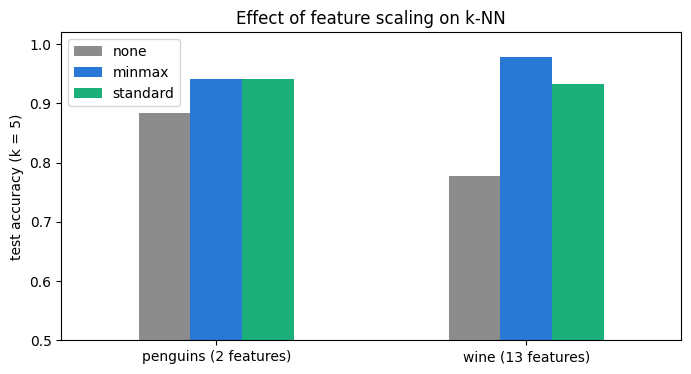

{'none': 0.7777777777777778, 'minmax': 0.9777777777777777, 'standard': 0.9333333333333333}


In [17]:
wine_scores = {}
for name, m in models.items():
    wine_scores[name] = m.fit(Xw_train, yw_train).score(Xw_test, yw_test)

df = pd.DataFrame({"penguins (2 features)": pen_scores, "wine (13 features)": wine_scores}).T
ax = df.plot.bar(rot=0, color=["#8C8C8C", "#2A78D6", "#1BAF7A"], figsize=(8, 4))
ax.set_ylim(0.5, 1.02)
ax.set_ylabel("test accuracy (k = 5)")
ax.set_title("Effect of feature scaling on k-NN")
plt.show()
print(wine_scores)


In [18]:
# CHECK C3 — do not edit
assert len(wine_scores) == 3 and None not in wine_scores.values(), "Score all three models on wine."
assert abs(wine_scores["none"] - 0.7778) < 0.01 and abs(wine_scores["minmax"] - 0.9778) < 0.01, "Fit on Xw_train, yw_train; score on Xw_test, yw_test."
print("✓ C3")

✓ C3


**Question C:** (1) Why does scaling help more on wine than on penguins? (2) In C1 the pipeline was fitted on `X_train` only. Explain in one sentence why fitting the scaler on **all** the data would be a mistake.

**Your answer (C):**

Wine has 13 features with very different scales, so scaling helps more. The scaler must learn from training data only. Using test data for scaling would cause data leakage.


---
# Part D — Choosing k (≈ 30 min)

### D1. Training accuracy versus cross-validation accuracy

**What this cell does:** for every k from 1 to 40 it records the **training** accuracy and the mean **5-fold cross-validation** accuracy of a scaled k-NN pipeline (penguins, training data only).

**Your task:** complete the two `# TODO` lines.

**Hint:** training accuracy: `pipe.fit(X_train, y_train).score(X_train, y_train)`. CV: `cross_val_score(pipe, X_train, y_train, cv=5).mean()`.

**Expected result:** training accuracy is **1.0 at k = 1** and falls; CV accuracy is best around **k = 7 (≈ 0.949)**. Takes a few seconds.

In [19]:
ks = range(1, 41)
train_acc, cv_acc = [], []
for k in ks:
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    train_acc.append(pipe.fit(X_train, y_train).score(X_train, y_train))
    cv_acc.append(cross_val_score(pipe, X_train, y_train, cv=5).mean())


In [20]:
# CHECK D1 — do not edit
assert None not in train_acc and None not in cv_acc, "Complete both TODO lines."
assert train_acc[0] == 1.0, "Training accuracy at k = 1 should be exactly 1.0 — fit and score on the TRAINING data."
best_k = list(ks)[int(np.argmax(cv_acc))]
assert best_k == 7 and abs(max(cv_acc) - 0.949) < 0.005, "CV accuracy: cross_val_score(pipe, X_train, y_train, cv=5).mean()."
print(f"✓ D1 — best k by CV = {best_k} (CV accuracy {max(cv_acc):.3f})")

✓ D1 — best k by CV = 7 (CV accuracy 0.949)


### D2. Plot the two curves

**What this cell does:** draws training and CV accuracy against k and marks the best k.

**Your task:** run it. Label the overfitting zone and the underfitting zone in your head (or with `plt.text`).

**Expected result:** the blue training curve starts at 1.0 and falls; the green CV curve rises, peaks at k = 7 and then slowly decreases.

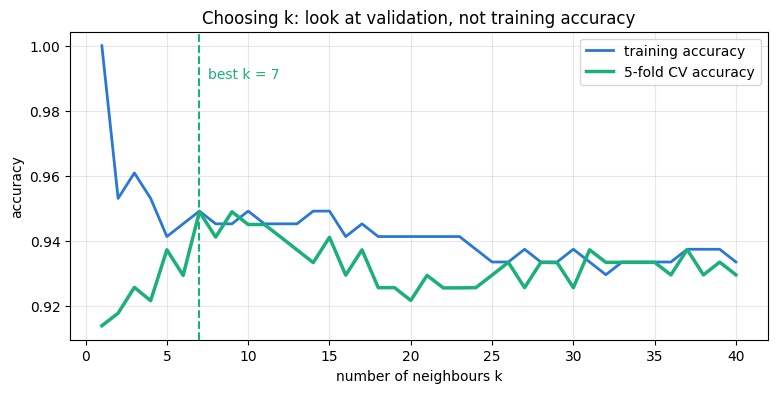

In [21]:
if None not in cv_acc:
    best_k = list(ks)[int(np.argmax(cv_acc))]
    plt.figure(figsize=(9, 4))
    plt.plot(ks, train_acc, color="#2A78D6", lw=2, label="training accuracy")
    plt.plot(ks, cv_acc, color="#1BAF7A", lw=2.5, label="5-fold CV accuracy")
    plt.axvline(best_k, ls="--", color="#1BAF7A"); plt.text(best_k + 0.5, 0.99, f"best k = {best_k}", color="#1BAF7A")
    plt.xlabel("number of neighbours k"); plt.ylabel("accuracy"); plt.legend(); plt.grid(alpha=0.3)
    plt.title("Choosing k: look at validation, not training accuracy"); plt.show()

### D3. GridSearchCV — k and the voting rule together

**What this cell does:** lets `GridSearchCV` try every **odd k from 1 to 29** and both voting rules, `weights="uniform"` (one neighbour = one vote) and `weights="distance"` (closer neighbours count more), with 5-fold CV on the training data.

**Your task:** complete the `param_grid` dictionary and the `GridSearchCV(...)` call.

**Hint:** in a pipeline the parameter names are `kneighborsclassifier__n_neighbors` and `kneighborsclassifier__weights` (step name, **two** underscores, parameter). Odd numbers: `range(1, 30, 2)`.

**Expected result:** `best_params_` and `best_score_` are printed; the best k is small-to-medium (single digits).

In [22]:
pipe = make_pipeline(StandardScaler(), KNeighborsClassifier())
param_grid = {
    "kneighborsclassifier__n_neighbors": list(range(1, 30, 2)),
    "kneighborsclassifier__weights": ["uniform", "distance"],
}
search = GridSearchCV(pipe, param_grid, cv=5)
search.fit(X_train, y_train)
print("best parameters:", search.best_params_)
print(f"best CV accuracy: {search.best_score_:.3f}")


best parameters: {'kneighborsclassifier__n_neighbors': 7, 'kneighborsclassifier__weights': 'uniform'}
best CV accuracy: 0.949


In [23]:
# CHECK D3 — do not edit
assert search is not None and hasattr(search, "best_params_"), "Create and fit the GridSearchCV."
assert len(search.cv_results_["params"]) == 30, "The grid should contain 15 values of k × 2 weightings = 30 combinations."
assert search.best_score_ >= 0.94, "Best CV accuracy should be about 0.95 — did you scale inside the pipeline?"
print("✓ D3 —", search.best_params_)

✓ D3 — {'kneighborsclassifier__n_neighbors': 7, 'kneighborsclassifier__weights': 'uniform'}


### D4. Test once

**What this cell does:** evaluates the model chosen by the grid search on the test set — **once**, at the very end.

**Your task:** complete `test_acc`.

**Hint:** `search.score(X_test, y_test)` — the search object has already been refitted with the best parameters on the whole training set.

**Expected result:** a test accuracy of about **0.94–0.95**, close to the CV estimate.

In [24]:
test_acc = search.score(X_test, y_test)
print("test accuracy of the chosen model:", test_acc)


test accuracy of the chosen model: 0.9534883720930233


In [25]:
# CHECK D4 — do not edit
assert test_acc is not None and abs(test_acc - search.score(X_test, y_test)) < 1e-9, "Use search.score(X_test, y_test)."
print(f"✓ D4 — test accuracy {test_acc:.3f}")

✓ D4 — test accuracy 0.953


**Question D:** (1) Why can't we choose k by training accuracy? (2) Why should we not choose k by looking at the **test** accuracy for every k? (3) Did `weights="distance"` help here?

**Your answer (D):**

Training accuracy is too optimistic, especially at k = 1. We should not choose k using the test set, because that would make the result unfair. Cross-validation chose k = 7. Distance voting did not help: uniform voting was best.


---
# Part E — k-NN for your midterm project (≈ 20 min, bring to IWST 3)

Apply everything to **your own data**. If your project is a **regression** task, replace `KNeighborsClassifier` by `KNeighborsRegressor` and the scoring by `scoring="neg_mean_absolute_error"`.

If you do not have your data with you today, set `PROJECT_CSV = TITANIC` to practise on the Titanic data (predict `survived`).

### E1. Titanic practice project

I used the Titanic data to predict survival. I chose six simple features and removed rows with missing ages. The data is included below, so the notebook can work offline.


In [26]:
# Titanic practice project (offline dataset)
TITANIC = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
PROJECT_CSV = TITANIC
TARGET = "survived"
FEATURES = ["pclass", "sex_male", "age", "fare", "sibsp", "parch"]
_titanic_data = "eNqNXNmuJDlufZ9vSQREagnpc9rjGnuAMdDoggf+fGsXN2XVywVuRmaEJG6Hh2T8/N+//v3Pf//4z8+ff//XHz9/fn7++L/PH//14/OPP/768fn5z//4+efnzz/++vt//819/Od//vjXjw/i4z7vg/EDH/c3qH//8aNf8LldgAez9/OaX9cw9R+V+isnfhXrlegf6D/ZT+kf1xuO7++P60chZj8/hPFhDO0W8OSE4uttqQiPe2P9BNiC3noJ4AHv292wXsN1Ddr9vKs/c1lupF2C9Lz1c6DbiG3zdZdRrsCZ+/ClPaKe1duOMfYL9Onvk2PAeVZ7YTGOpztjl+WBuvvQV4XzsMCTr67zhnaPtlqxsybTfX5IpIDrgfvGvp+C3x+ftU+pYcEt57HE9sB6tyiXk68S6upUV+szOSO90vkAKH2lbU2+S5PuK79zPfQWucTM7xGarKpivOiyVNMqlipc1ApR7/SKU0vtwMA9Yon9DDI+sNTqPLhJMCKRydmnXHk7LK5Q6+zzEiwKoYSh6hjg3Ua21LltuTzhjfMKMgPpD4PbwRHNbOce4IntoIGff5eMKQPDvKGpyJcTXt+rC0vthmidQX0YX3TbSrW41DSpWQg/zPZ1Ie3Q11zNHPt+2FaxLJtgMkxN9RM8ZewTju4fvad3Aa4jfutIpGKnxj+VM/YD3r+AdqOqm+UT6cfLS1NLpIaV3XYNSwm77XqiC/NWYTy4dMPaXxeGQgSI1UNP98gPTW+360Z+YLl0qjbvjhiBbSz1n6Tm65H5KpSPWHdK/ISQyt4rCXTJhhpmAnJz7A+I6QnHcazfxL7WFL85GaX12526p26/n5DjptNi0Aewi4Q/ELvZOn74/RZl6xozoPxa3ii8Ne4KPesHv8+RrqYZeZVvbq6aCrGdWA0JviuOt7e6tQ89c9RnS8EMlFjsjx0PkkeL0zBDkFrc5Vp/FqUBxbLwzNU7zXu/MDaaTmheh9m2U/fkhyIz1e/BEkewBKKugbuRg0zy2JrWHCtmDS2uyx8CJr6tiyufxZ4Lx7JQ+B7H3btn3morOA1Qr1RNf79LkzFEEfreFfqk1YYWCYgdcuW3IiCOYJYxyjMdOh0oduQRoEjxv647Yhnah/MH6fy78mLdSxweEdiyDtQLtgPCm+Id1xYFID3q1a4RoEcxMdWLLTRAAw6IQAvMKquTaN9V0sSh70C1rkeR6muVWviLVk9L1tIMU2bxVwEYiRMmB4HENBsuDVGF+QkaR8biaHTrNqKzku7qyoOQXmGG/ZzqFbmLHRCFa5/x+VVett9peFlQoTIphRyIBx75cc8v0kALRPg4bP+lYpgPLseLI1XTepe4cgDycces+rgjjJAVdabXt1yxceIbiw0daQ8f3LD/OB97dNSDBP/9odXp+4O9ePSvOx55HtVId8swk8ojP6m0zC7TlYSZCoJ0+B1TVwm+FrIwPGZ3TtZTQcDWLcUyQxnGqVYnTekponBAIS4EB59AEVzUfq8HAQ5yFsDty1F4Kcjk85w8ybDBQN1FiTGNvDspJwH5hHt2q7aHkKo1+v7pScd7KpefF1RK67je+q3l9X8dhpjk8YBcqTaFJKth0glUiO3HIImEZhEYuecZS5e+luRFFK4bhMPSvsgPyicZlmkEsSy5uxAzyS9UGJQWOH6ZcSMh3PPqzpvs3NrZ4ehsboT+4IKycx6smTNVwu5KXp7fMPKO0izIH+JM1ETA7JpqgpOBqsOwcioZZA4feCKSD3Q3nFrkMLTLvhM8fLuBhlgq+bjQjM4uCCL+bjmfmZPyHHMYv58El1PUGzV/GlEGLyduhiMbxwKvtSSaq5zj0TBq3FttIIIdCJi1AEG3xUlWZOZjXiR2YGe9OLAlmqHcoOyYk5PUqZWxYxGRBkmqA16ndlF4r3Nk4ZJU19tHKT+W0RA1m9To9nSX00GCFCuCwFc/VOblyj1yoG4c/VBtkGHPu0mXiJDU99TlLZimmfK/r2Z2wsKtKzYTRFmB0YlhSKA6ywQ3+6e9SCFuBGbMG+EZ7XgwTCQRJLu8MgwUgbBhhHgMQ64HYmyYS1Wxg6n0XOj9Kk5vUVru0MvwNQ/xSkEXZsABvJM4ju4KrXiuczqfbG4q3eAXkT1Y0azmDdvNy6OA+jcdLLopQlBkTiQboOiye9YRvEAkLFVs7z0ukqV0+qVmh2Xkb06hRX1K7DA3q2ojvxFX3IMChCRxa0E8KKZiplvSuwtKaMNZVRhZFEiSUdo7CwBM58AwkpHrfMnigNe7cgvqVs5ZWsWjIHdZQw/xydrxTXIsRzOwa1aIoa3zdc/JZYKXBwaB5j2Aeq12UmoLw2wp23HRtw3S/SPJpn4Mhnq3A/DxTpnCokzb6fEF7ztUW87Ze3Xyg9jMPQ+SIGJ4bcOp1aSkGCT6kIin1DWwKgRWh0xzaaoYGyRfubcTVP0OniAqmOlaJ8RgMiRxRiannHT3KSk8OXVig53nSCh8kBmFRImcYTATjUlnex0zZwlTnApB5HS1SftRT3LUelheh+X5K23DHk42LRKX7n/iS2s6BJQRpQaSFPQSDrNGr6IC93CkaEe0uDqvFO/Ft0M9FUqrUMHBFhwzxxBN/9k/ZqWqU1w2krqpY4fHR6LJBg1ns3NSKpfMTbEr3sqRF8hhqKGimCIoSrzwLZ0qLBoEjnjGI1M85TVuFdGsQDJsaWWhkicjPA6ywp25dVJe/VXlexW5FxnEiO0ZNSxEsKA3z12jJG8VHhcAW0ORfiGefhLekGDuyoi3PU+vGZioy8RxlEFx3d3mZmIPRklSWgei5XRI9Zs1MRwzpvV+DRykps2iO0jWs5PkdYsqb4Ei0pBj/d1w8SVMLGfm4vMOVh8FF/GlTQe/tQPwRFZXVlmh+uqZWRZg5AwjiiMJYhQ8jcwcCYwGTXjTiLuqYLJCeeMudv+PM6rtFq3uQYJbJJVKgllZvcIZHQN5bFwW4XyxK1iYbkwUqDIZeQCrPNDCGvOYrIipmkQicFhM+MFGaEWTDn6NfJ+zu1/L6qmuW0OxngEQvkYmM8DYfH6K24Qt5qy3iOETZaMDJXHwG3e2vj/BJ+g6h1Erg0stA1ePjRZ2nr6bn/mAHDP5B3G6aOueRe1A4Ur8JYNnVVveGHZoi0s8R+7VFFcym0V0YcgN/18kNho9UdtdSOsgdTCFSboCY+9zWNTLgUIspnq4mPLi7uXZo52WSrpBuAQvdbl11ABKbrgdPywj4f2OnlIKx6WGm2ji+D62eyH9SQ8QXlN6ye5dajcpzb5ZMd27/W2+gx6ZywNOdgRQvRIWoctYUeyK1M5mCykYLJXmhyz+/dIE6oONuHtfWpanFbIdD40u0szhl6ZqaGXNWFiPsUq8rguKyPfCSZJuMsqxIHO+R+xUcf3Y4nsYfQ6NanjysmOJtol8jz9T+C5IcDfjdKR9a5QBQaOPppjdY5oOi447OM/ItmpdWapLN2xOBf0e508C2hJwPvTftcbN6sc6LxLWyGOO8qyRWzptkaqGGl34Zd8qofR14B79K/lBtaC2clD8VeQElqTINP6zqu682+m1ih6JNuQumbxawJRB2Lz46VbOjIpSNpN2LyAhN6OVPyIygH+QH63hS6/4/ppg82m1xuhNjX770jGFZiN158Dwc/XqMTsOpAznuiCR5nB09PeKt+UUXvG/YnqtPF0WsCkP5L62aAfWO/YlkmzhVo17VaaugD3LEKD3jfEmW5NaNJc4AdPmL6y+LseBkXdXR/+KAp/doiDFAq6qKBr+wGZEQnlUu8voaoCNtnkzE+25O4Ab+CVg/cO6rzvSpfKO7yCHIxQoZu0RLeDpEZVh8JR+nF/PooMLiOQIxY2ivm2C8Ux5FN4fHm81DRl+RYGRmkeelTJ+PoJ9OEIrrGRHqdg0yLNw60vkLJbFPSxIHL+BJ5XZcR82fA8aPEs2EvzdEtrXGGzDA+mrKGt/jhesaosf001hzTsoH+2NDhHjzCCZEXiU4cNj57gku+AC3FmVqs9nb/TNU1IJWdQevkCgnEKV/FIt5xx7b/J3urL/IU1gskYzlJC3Nb6zXZSHw8FStsK3roGYPYQKqkeWoVL54g3phFdWWIRwKcHw2qExbX0WRMVwPNyoiqiZWyHxfHNVxsAqPr2z4+177aLl80EsIpg8gb+0uw2XEQfu03yz7uDpK/MWv4ZqhknUwE4Fh8M/Y5ZvbdnFeyvfN//Gxx/l6fYcFlSfGqN5aJXQZFJoX+Jxn3YvBL5qKEaMrkU1LoOOsMwW4afr/SOTSwTek87T1kLihLePr6goAsfws8PBasM1sd9m1vb++pyUd2bPWBOvnATxaOZFVitKoXNVV1bnxs1zlomTSbQAuDpYHNNM1hBkTtRciyuip5HsYN1cph43WoHzJnTc7hp3gfcKR4OU0XQVjtmD+LXBjzO4ZF6H56/haAirsxlp4SwxqRGSYI992OhidYdGHgUXgSJ5nkxKFyyBHDB21JTRQFK686178HiyWtlKbGSXbmsoqMk8suNLSfjLUFHwMihszg41KT3aYE83ARBDISUs3JM+gqUl5K0qWOv4OHvT1Zox0LkGEHpRnhw099X32ckm+CQB9EgTHQgUC15RSy+xKD1vU3Q1ujPimudK4iyp7Giw5Pcxh21Xv2evh5pHaCTwEGdF1PtX8tMwsnJnzujXWD2mdODimSS/riwgOQE5kJDcOsWQwIWhNdXxFwyES/sTyLCd6CuaSRVY6AiNChDkW/V+FRaoIqrWIm7J5ZLyhsg7iyk6uLBISHrOvs0Q8zDEuUXNjvGYogvWc0Y25C0QIVVnFti1MHxW9XU+O2+QWqDi1RyLM9qI05i2EVFo8jZOSybY41hO5nBngXq8De8UzyjKdEBhaLeKcfE23BpZiKDSLdzQnRhxp5MQlje+BMbLx3TcngBOzymNM9PMLY31M/+iLm2BFwooqYsfDaNgIFneTUjJCqPr6TJe1QPdC5IfhMSadVW/ngIZ3SSMN7aooj+ddPI7yV+tenS0XY4t6xqov3YVdlHtjIgM1bd0WnctZlkPuAxSmqU72VlAmH3FXx5/DiL153DJfEVDUuVpNvdjcPKgOrq3sjVmTsJKMd7MaXfNrufH63a5YEkqZN3vstb43gqpqB1OJGrjNVSI3xoOaJnaeHsCdVk0yfcaanhWI7eF1X3yxiG8L1Nnjm1PQRap7Da6BUxsBPkaUCbrlvzdesXefUDflsDGlm9DEpAkt2wNSBL/lm44S3O2vlyIxg6S+pSqbgP0Ix9L2ZzrFTUPFsQ2G+Zu7zNC3htMuq+BRiTdbeaeqvU1pijk2QOuNRYPNtnuiz2+opKNXx1hd1NGpJ8ITyd3hfQjyTdBWYNgSVdajocxpjSMTU3nbjMbjdh0cuy3m2pqdsSBguOEBOdYexlQT8OzGjDt2DbmcPG9RC28JT1N6NL9cH6EzgnPvTpGp5gDPEjf4SPfwMWZOvqWGaP9zn7LlL+N5Ix2D2/WBNY8BBjEiTFUrxsT1Ct2SAFcNTcQukG7KquS4u3x2N4hX5/pf3swf2Zo8XcGiOO3QtUG+Kxl2GpxChcze8OteZKO8FlzDb506p11mMsRTslZeDXUNhK/NTrCnGSEW//YAK6TCXTslUFmPR2GToPrxKETr1DpoA2MkiSNHL8Y6b+PG+BtQGEOE2cFuAYv4YzwrGfZwvUdCena0xD0JCkQ7KxmFcLLXhYlmjqDIWxJiHDqKAfVS1N+45VF1B0nNjwFqiaoZ0Kt98cwIsGtqKuKwe7SUOnsSs7ET4MvNyfH5TSft+ZMD8w7WXcyEaFnQ4T/D29VurM="

# This copy has the same needed columns as the practice Titanic data.
if PROJECT_CSV == TITANIC:
    data = pd.read_csv(StringIO(zlib.decompress(base64.b64decode(_titanic_data)).decode("utf-8")))
else:
    data = pd.read_csv(PROJECT_CSV)
if "sex" in data.columns:
    data["sex_male"] = (data["sex"] == "male").astype(int)
data = data[FEATURES + [TARGET]].dropna()
Xp, yp = data[FEATURES].to_numpy(), data[TARGET].to_numpy()
Xp_train, Xp_test, yp_train, yp_test = train_test_split(Xp, yp, test_size=0.25, random_state=0)
print("train", Xp_train.shape, "| test", Xp_test.shape)
print(data[FEATURES].describe().T[["min", "max", "std"]].round(2))


train (535, 6) | test (179, 6)
           min     max    std
pclass    1.00    3.00   0.84
sex_male  0.00    1.00   0.48
age       0.42   80.00  14.53
fare      0.00  512.33  52.92
sibsp     0.00    5.00   0.93
parch     0.00    6.00   0.85


### E2. Tune a k-NN pipeline and compare with your first model

**What this cell does:** runs a grid search for a scaled k-NN on your training data, tests the best model once, and compares it with a scaled logistic regression (or your Week 4/5 model).

**Your task:** just run it once E1 works. Copy the printed table into your midterm notebook.

**Expected result:** a small table with the CV and test scores of both models. (Titanic practice: both models ≈ 0.78–0.82 accuracy.)

In [27]:
from sklearn.linear_model import LogisticRegression
if PROJECT_CSV is not None:
    knn_search = GridSearchCV(make_pipeline(StandardScaler(), KNeighborsClassifier()),
                              {"kneighborsclassifier__n_neighbors": range(1, 40, 2),
                               "kneighborsclassifier__weights": ["uniform", "distance"]}, cv=5).fit(Xp_train, yp_train)
    logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    logreg_cv = cross_val_score(logreg, Xp_train, yp_train, cv=5).mean()
    logreg.fit(Xp_train, yp_train)
    summary = pd.DataFrame({
        "model": [f"k-NN {knn_search.best_params_}", "logistic regression"],
        "CV score": [knn_search.best_score_, logreg_cv],
        "test score": [knn_search.score(Xp_test, yp_test), logreg.score(Xp_test, yp_test)]}).round(3)
    print(summary.to_string(index=False))

                                                                                     model  CV score  test score
k-NN {'kneighborsclassifier__n_neighbors': 19, 'kneighborsclassifier__weights': 'uniform'}     0.813       0.788
                                                                       logistic regression     0.798       0.816


**Your answer (E — for IWST 3):**

I used Titanic data. Cross-validation chose k = 19 with uniform voting for k-NN. k-NN got 0.788 test accuracy, while logistic regression got 0.816. I will present logistic regression next week because its test score was better.


*For IWST 3, write 3–4 sentences: which k and weighting were chosen, how they were chosen, how k-NN compares with your first model, and which model you will present next week and why.*

---
## Reflection (5 min)

1. In one sentence: what is the k-NN rule?
2. Name the two most important practical rules for k-NN that you used today.
3. What surprised you most in this lab?

**Your answer (Reflection):**

1. k-NN finds the nearest points and uses the most common class.
2. Scale the features and choose k with cross-validation.
3. I was surprised that changing the scale can change the prediction.


---
**Submit:** *Runtime → Restart and run all*, check that every CHECK prints ✓, rename the file `Lab06_<Surname>_<Name>.ipynb` and upload it to the course page.